# Insight360: E-Commerce Data Exploration

This notebook explores the nine raw Olist datasets for structure, quality, identifiers, relationships, distributions, and potential issues to investigate in later validation work. It is descriptive: patterns do not establish causation. Source CSV files are loaded without modification; analytical date and numeric values are derived only in memory where needed.

## Imports and project setup

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Locate the repository whether the notebook is launched from the project root
# or from the notebooks directory.
PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "config.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import EXPECTED_FILES
from src.ingestion.loader import load_all
from src.ingestion.profiler import (
    DEFAULT_KEY_MAP,
    duplicate_report,
    missing_report,
    profile_table,
    unique_report,
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data directory: {RAW_DIR}")

Project root: D:\Insight360
Raw data directory: D:\Insight360\data\raw


## Load all nine CSV files

In [2]:
file_check = {name: (RAW_DIR / name).is_file() for name in EXPECTED_FILES}
if not all(file_check.values()):
    missing = [name for name, exists in file_check.items() if not exists]
    raise FileNotFoundError(f"Missing required raw CSV files: {missing}")

dfs = load_all(RAW_DIR)
assert len(dfs) == 9
print(f"Loaded {len(dfs)} tables: {', '.join(dfs)}")

Loaded 9 tables: orders, customers, order_items, payments, reviews, products, sellers, geolocation, category_translation


## Dataset dimensions, columns, and data types

In [3]:
structural_profiles = pd.DataFrame(
    [profile_table(df, name) for name, df in dfs.items()]
)
display(structural_profiles[["table", "row_count", "column_count", "memory_usage_bytes"]])
for name, df in dfs.items():
    print(f"\n{name}: {list(df.columns)}")
    print(df.dtypes.astype(str).to_dict())

,table,row_count,column_count,memory_usage_bytes
0,orders,99441,8,55508758
1,customers,99441,5,32452152
2,order_items,112650,7,52858041
3,payments,103886,5,30580476
4,reviews,99224,7,45192710
5,products,32951,9,16531471
6,sellers,3095,4,759041
7,geolocation,1000163,5,301334774
8,category_translation,71,2,9436



orders: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
{'order_id': 'str', 'customer_id': 'str', 'order_status': 'str', 'order_purchase_timestamp': 'str', 'order_approved_at': 'str', 'order_delivered_carrier_date': 'str', 'order_delivered_customer_date': 'str', 'order_estimated_delivery_date': 'str'}

customers: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
{'customer_id': 'str', 'customer_unique_id': 'str', 'customer_zip_code_prefix': 'str', 'customer_city': 'str', 'customer_state': 'str'}

order_items: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
{'order_id': 'str', 'order_item_id': 'str', 'product_id': 'str', 'seller_id': 'str', 'shipping_limit_date': 'str', 'price': 'str', 'freight_value': 'str'}

payments: ['order_id', 'paym

## Missing-value analysis

In [4]:
missing_values = missing_report(dfs)
display(missing_values.sort_values(["table", "null_pct"], ascending=[True, False]).reset_index(drop=True))

,table,column,null_count,null_pct
0,orders,order_delivered_customer_date,2965,2.981668
1,orders,order_delivered_carrier_date,1783,1.793023
2,orders,order_approved_at,160,0.160899
3,products,product_category_name,610,1.851234
4,products,product_name_lenght,610,1.851234
5,products,product_description_lenght,610,1.851234
6,products,product_photos_qty,610,1.851234
7,products,product_weight_g,2,0.006070
8,products,product_length_cm,2,0.006070
9,products,product_height_cm,2,0.006070


## Full-row duplicate analysis

In [5]:
duplicate_summary = duplicate_report(dfs, DEFAULT_KEY_MAP)
display(duplicate_summary[["table", "full_row_duplicate_count", "key_duplicate_count"]])

,table,full_row_duplicate_count,key_duplicate_count
0,orders,0,0.0
1,customers,0,0.0
2,order_items,0,0.0
3,payments,0,0.0
4,reviews,0,814.0
5,products,0,0.0
6,sellers,0,0.0
7,geolocation,261831,NaN
8,category_translation,0,0.0


## Identifier uniqueness and key inspection

In [6]:
identifier_report = duplicate_summary[["table", "key_columns", "key_duplicate_count"]].copy()
identifier_report["key_columns"] = identifier_report["key_columns"].map(
    lambda columns: ", ".join(columns) if columns else "Not configured"
)
display(identifier_report)
display(unique_report(dfs).query("column in ['order_id', 'customer_id', 'customer_unique_id', 'product_id', 'seller_id', 'review_id']"))

,table,key_columns,key_duplicate_count
0,orders,order_id,0.0
1,customers,customer_id,0.0
2,order_items,"order_id, order_item_id",0.0
3,payments,"order_id, payment_sequential",0.0
4,reviews,review_id,814.0
5,products,product_id,0.0
6,sellers,seller_id,0.0
7,geolocation,Not configured,NaN
8,category_translation,product_category_name,0.0


,table,column,distinct_value_count
0,orders,order_id,99441
1,orders,customer_id,99441
8,customers,customer_id,99441
9,customers,customer_unique_id,96096
13,order_items,order_id,98666
15,order_items,product_id,32951
16,order_items,seller_id,3095
20,payments,order_id,99440
25,reviews,review_id,98410
26,reviews,order_id,98673


## Dataset relationships overview

The expected relationship paths are:

- **Orders to customers:** `orders.customer_id` references `customers.customer_id`. `customer_unique_id` in the customer table identifies a persistent customer across customer records.
- **Order items to orders, products, and sellers:** `order_items.order_id` references `orders.order_id`; `product_id` references `products.product_id`; and `seller_id` references `sellers.seller_id`.
- **Payments to orders:** `payments.order_id` references `orders.order_id`.
- **Reviews to orders:** `reviews.order_id` references `orders.order_id`. An order may have more than one review record; do not assume one review per order.
- **Products to category translation:** `products.product_category_name` corresponds to `category_translation.product_category_name`.
- **Customers and sellers to geolocation:** `customers.customer_zip_code_prefix` and `sellers.seller_zip_code_prefix` correspond to `geolocation.geolocation_zip_code_prefix`. ZIP prefixes repeat in geolocation, so this is not a unique-key relationship.

The tables have different grains: orders are at the order level; order items are at the order-line level (identified by the order and item number); payments are at the payment-entry level (identified by the order and payment sequence); reviews are at the review-record level; and geolocation is at the location-record level. Customers, products, sellers, and category translations are represented by their respective entity or category records.

Because one order can have multiple item rows and multiple payment rows, joining order items directly to payments on `order_id` can create the product of those row counts for that order. Such a join multiplies rows and inflates sums and counts. This notebook analyzes item and payment grains separately unless a relationship is explicitly needed and constrained. This section documents expected relationships only; it does not implement D1-T10 foreign-key or relationship validation.

## Question 1 — What are the sizes of all nine datasets?

In [7]:
dataset_sizes = pd.DataFrame(
    [{"table": name, "rows": len(df), "columns": len(df.columns)} for name, df in dfs.items()]
)
display(dataset_sizes)

,table,rows,columns
0,orders,99441,8
1,customers,99441,5
2,order_items,112650,7
3,payments,103886,5
4,reviews,99224,7
5,products,32951,9
6,sellers,3095,4
7,geolocation,1000163,5
8,category_translation,71,2


In [8]:
display(Markdown(f"**Interpretation.** All {len(dataset_sizes)} datasets are loaded. The largest by row count is {dataset_sizes.loc[dataset_sizes.rows.idxmax(), 'table']} ({int(dataset_sizes.rows.max()):,} rows); the smallest is {dataset_sizes.loc[dataset_sizes.rows.idxmin(), 'table']} ({int(dataset_sizes.rows.min()):,} rows)."))

**Interpretation.** All 9 datasets are loaded. The largest by row count is geolocation (1,000,163 rows); the smallest is category_translation (71 rows).

## Question 2 — Which columns contain missing values?

In [9]:
missing_by_table = missing_values.groupby("table", as_index=False).agg(
    columns_with_missing=("column", "count"), missing_cells=("null_count", "sum")
)
display(missing_values)
display(missing_by_table)

,table,column,null_count,null_pct
0,orders,order_approved_at,160,0.160899
1,orders,order_delivered_carrier_date,1783,1.793023
2,orders,order_delivered_customer_date,2965,2.981668
3,reviews,review_comment_title,87656,88.341530
4,reviews,review_comment_message,58247,58.702532
5,products,product_category_name,610,1.851234
6,products,product_name_lenght,610,1.851234
7,products,product_description_lenght,610,1.851234
8,products,product_photos_qty,610,1.851234
9,products,product_weight_g,2,0.006070


,table,columns_with_missing,missing_cells
0,orders,3,4908
1,products,8,2448
2,reviews,2,145903


In [10]:
display(Markdown(f"**Interpretation.** {len(missing_values)} columns across {missing_values.table.nunique() if not missing_values.empty else 0} tables contain missing values, totaling {int(missing_values.null_count.sum()) if not missing_values.empty else 0:,} missing cells. The report lists each affected column and its percentage of table rows."))

**Interpretation.** 13 columns across 3 tables contain missing values, totaling 153,259 missing cells. The report lists each affected column and its percentage of table rows.

## Question 3 — Are there duplicate rows?

In [11]:
full_row_duplicates = duplicate_summary[["table", "full_row_duplicate_count"]].copy()
display(full_row_duplicates)
total_full_row_duplicates = int(full_row_duplicates.full_row_duplicate_count.sum())

,table,full_row_duplicate_count
0,orders,0
1,customers,0
2,order_items,0
3,payments,0
4,reviews,0
5,products,0
6,sellers,0
7,geolocation,261831
8,category_translation,0


In [12]:
display(Markdown(f"**Interpretation.** Across all tables, {total_full_row_duplicates:,} extra full-row duplicate records are counted beyond each first occurrence. Tables with any are: {', '.join(full_row_duplicates.loc[full_row_duplicates.full_row_duplicate_count.gt(0), 'table'].tolist()) or 'none'}."))

**Interpretation.** Across all tables, 261,831 extra full-row duplicate records are counted beyond each first occurrence. Tables with any are: geolocation.

## Question 4 — Are the identifiers unique where expected?

In [13]:
configured_identifiers = identifier_report[identifier_report.key_columns.ne("Not configured")].copy()
display(configured_identifiers)
nonunique_expected = configured_identifiers[configured_identifiers.key_duplicate_count.fillna(0).gt(0)]
nonunique_details = ", ".join(
    f"{row.table}: {int(row.key_duplicate_count):,}"
    for row in nonunique_expected.itertuples()
) or "none"

,table,key_columns,key_duplicate_count
0,orders,order_id,0.0
1,customers,customer_id,0.0
2,order_items,"order_id, order_item_id",0.0
3,payments,"order_id, payment_sequential",0.0
4,reviews,review_id,814.0
5,products,product_id,0.0
6,sellers,seller_id,0.0
8,category_translation,product_category_name,0.0


In [14]:
display(Markdown(f"**Interpretation.** {len(configured_identifiers)} configured candidate identifiers or composite identifiers are checked. {len(nonunique_expected)} have repeated key values beyond the first occurrence ({nonunique_details}). These are key-map checks, not foreign-key validation; geolocation intentionally has no configured unique key."))

**Interpretation.** 8 configured candidate identifiers or composite identifiers are checked. 1 have repeated key values beyond the first occurrence (reviews: 814). These are key-map checks, not foreign-key validation; geolocation intentionally has no configured unique key.

## Question 5 — What is the distribution of order statuses?

In [15]:
status_counts = dfs["orders"]["order_status"].value_counts(dropna=False).rename_axis("order_status").reset_index(name="orders")
status_counts["percent"] = status_counts.orders / len(dfs["orders"]) * 100
display(status_counts)

,order_status,orders,percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


In [16]:
display(Markdown(f"**Interpretation.** The most frequent status is {status_counts.iloc[0].order_status} ({int(status_counts.iloc[0].orders):,} orders, {status_counts.iloc[0].percent:.1f}% of orders). This describes the observed status mix."))

**Interpretation.** The most frequent status is delivered (96,478 orders, 97.0% of orders). This describes the observed status mix.

## Question 6 — How do orders change over time?

,month,orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


,month,orders
13,2017-11,7544
14,2017-12,5673
15,2018-01,7269
16,2018-02,6728
17,2018-03,7211
18,2018-04,6939
19,2018-05,6873
20,2018-06,6167
21,2018-07,6292
22,2018-08,6512


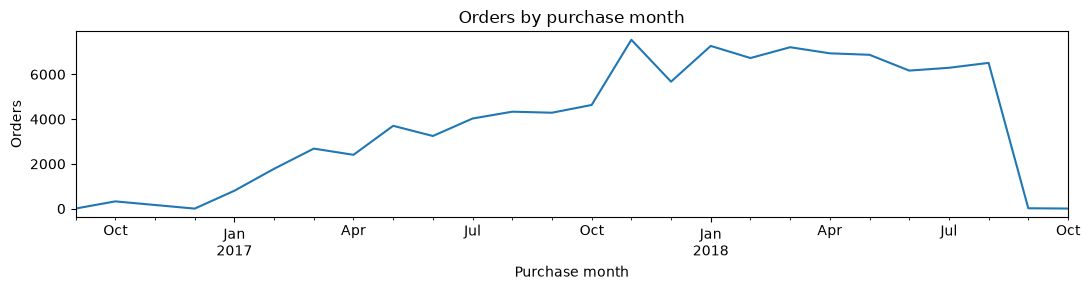

In [17]:
purchase_ts = pd.to_datetime(dfs["orders"]["order_purchase_timestamp"], errors="coerce")
orders_by_month = purchase_ts.dropna().dt.to_period("M").value_counts().sort_index()
monthly_orders = orders_by_month.rename_axis("month").rename("orders").reset_index()
display(monthly_orders.head(12))
display(monthly_orders.tail(12))
ax = orders_by_month.plot(figsize=(11, 3), title="Orders by purchase month")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Orders")
plt.tight_layout()
plt.show()

In [18]:
display(Markdown(f"**Interpretation.** Purchase timestamps parsed for {int(purchase_ts.notna().sum()):,} of {len(purchase_ts):,} rows. The monthly series spans {monthly_orders.month.iloc[0] if len(monthly_orders) else 'no valid months'} through {monthly_orders.month.iloc[-1] if len(monthly_orders) else 'no valid months'}; the plotted counts show the observed month-to-month pattern."))

**Interpretation.** Purchase timestamps parsed for 99,441 of 99,441 rows. The monthly series spans 2016-09 through 2018-10; the plotted counts show the observed month-to-month pattern.

## Question 7 — How many unique persistent customers exist?

In [19]:
persistent_customer_count = dfs["customers"]["customer_unique_id"].nunique(dropna=True)
print(f"Unique non-null customer_unique_id values: {persistent_customer_count:,}")

Unique non-null customer_unique_id values: 96,096


In [20]:
display(Markdown(f"**Interpretation.** The customer table contains {persistent_customer_count:,} distinct non-null `customer_unique_id` values. This persistent-customer identifier is used instead of `customer_id`."))

**Interpretation.** The customer table contains 96,096 distinct non-null `customer_unique_id` values. This persistent-customer identifier is used instead of `customer_id`.

## Question 8 — How many repeat customers exist?

In [21]:
customer_order_map = dfs["orders"][ ["order_id", "customer_id"] ].merge(
    dfs["customers"][ ["customer_id", "customer_unique_id"] ],
    on="customer_id", how="left", validate="many_to_one"
)
orders_per_persistent_customer = customer_order_map.groupby("customer_unique_id")["order_id"].nunique()
repeat_customers = orders_per_persistent_customer[orders_per_persistent_customer > 1]
print(f"Persistent customers with more than one distinct order: {len(repeat_customers):,}")
print(f"Persistent customers represented in mapped orders: {orders_per_persistent_customer.index.notna().sum():,}")

Persistent customers with more than one distinct order: 2,997
Persistent customers represented in mapped orders: 96,096


In [22]:
display(Markdown(f"**Interpretation.** Using `customer_unique_id` and counting distinct order IDs, {len(repeat_customers):,} mapped persistent customers have more than one order. The customer mapping uses a validated many-to-one join to avoid multiplying order rows."))

**Interpretation.** Using `customer_unique_id` and counting distinct order IDs, 2,997 mapped persistent customers have more than one order. The customer mapping uses a validated many-to-one join to avoid multiplying order rows.

## Question 9 — How many items are there per order?

In [23]:
items_per_order = dfs["order_items"].groupby("order_id").size().rename("item_rows")
display(items_per_order.describe().to_frame().T)
print(f"Orders represented in item table: {items_per_order.size:,}")
print(f"Total item rows: {len(dfs['order_items']):,}")

,count,mean,std,min,25%,50%,75%,max
item_rows,98666.0,1.141731,0.538452,1.0,1.0,1.0,1.0,21.0


Orders represented in item table: 98,666
Total item rows: 112,650


In [24]:
display(Markdown(f"**Interpretation.** The item table contains {len(dfs['order_items']):,} rows across {items_per_order.size:,} orders. The displayed distribution is calculated at the order-item grain and does not include payment rows."))

**Interpretation.** The item table contains 112,650 rows across 98,666 orders. The displayed distribution is calculated at the order-item grain and does not include payment rows.

## Question 10 — How many payments are there per order?

In [25]:
payments_per_order = dfs["payments"].groupby("order_id").size().rename("payment_rows")
display(payments_per_order.describe().to_frame().T)
print(f"Orders represented in payment table: {payments_per_order.size:,}")
print(f"Total payment rows: {len(dfs['payments']):,}")

,count,mean,std,min,25%,50%,75%,max
payment_rows,99440.0,1.04471,0.381166,1.0,1.0,1.0,1.0,29.0


Orders represented in payment table: 99,440
Total payment rows: 103,886


In [26]:
display(Markdown(f"**Interpretation.** The payment table contains {len(dfs['payments']):,} rows across {payments_per_order.size:,} orders. This distribution is calculated independently from order items to preserve the two table grains."))

**Interpretation.** The payment table contains 103,886 rows across 99,440 orders. This distribution is calculated independently from order items to preserve the two table grains.

## Question 11 — Are there orders without corresponding items or payments?

In [27]:
order_ids = set(dfs["orders"]["order_id"].dropna())
item_order_ids = set(dfs["order_items"]["order_id"].dropna())
payment_order_ids = set(dfs["payments"]["order_id"].dropna())
orders_without_items = order_ids - item_order_ids
orders_without_payments = order_ids - payment_order_ids
coverage = pd.DataFrame([
    {"check": "Orders without items", "orders": len(orders_without_items)},
    {"check": "Orders without payments", "orders": len(orders_without_payments)},
    {"check": "Item order IDs absent from orders", "orders": len(item_order_ids - order_ids)},
    {"check": "Payment order IDs absent from orders", "orders": len(payment_order_ids - order_ids)},
])
display(coverage)

,check,orders
0,Orders without items,775
1,Orders without payments,1
2,Item order IDs absent from orders,0
3,Payment order IDs absent from orders,0


In [28]:
display(Markdown(f"**Interpretation.** Set comparisons find {len(orders_without_items):,} order IDs without item rows and {len(orders_without_payments):,} without payment rows. The comparisons do not join the item and payment tables, so their rows cannot multiply."))

**Interpretation.** Set comparisons find 775 order IDs without item rows and 1 without payment rows. The comparisons do not join the item and payment tables, so their rows cannot multiply.

## Question 12 — What is the distribution of review scores?

In [29]:
review_scores = dfs["reviews"]["review_score"].value_counts(dropna=False).sort_index().rename_axis("review_score").reset_index(name="review_rows")
review_scores["percent"] = review_scores.review_rows / len(dfs["reviews"]) * 100
display(review_scores)

,review_score,review_rows,percent
0,1,11424,11.513344
1,2,3151,3.175643
2,3,8179,8.242965
3,4,19142,19.291704
4,5,57328,57.776344


In [30]:
display(Markdown(f"**Interpretation.** The review table has {len(dfs['reviews']):,} rows. Its most common score is {review_scores.loc[review_scores.review_rows.idxmax(), 'review_score']} ({int(review_scores.review_rows.max()):,} rows). Review rows are not assumed to be one per order."))

**Interpretation.** The review table has 99,224 rows. Its most common score is 5 (57,328 rows). Review rows are not assumed to be one per order.

## Question 13 — Which product categories are most common?

In [31]:
category_counts = (
    dfs["products"]["product_category_name"]
    .value_counts(dropna=False)
    .rename_axis("product_category_name")
    .reset_index(name="product_rows")
)
display(category_counts.head(10))

,product_category_name,product_rows
0,cama_mesa_banho,3029
1,esporte_lazer,2867
2,moveis_decoracao,2657
3,beleza_saude,2444
4,utilidades_domesticas,2335
5,automotivo,1900
6,informatica_acessorios,1639
7,brinquedos,1411
8,relogios_presentes,1329
9,telefonia,1134


In [32]:
display(Markdown(f"**Interpretation.** By product-row count, the most common category is {category_counts.iloc[0].product_category_name} ({int(category_counts.iloc[0].product_rows):,} products). Null categories remain visible if present; this ranking is not a sales ranking."))

**Interpretation.** By product-row count, the most common category is cama_mesa_banho (3,029 products). Null categories remain visible if present; this ranking is not a sales ranking.

## Question 14 — Are there unusual product-price and freight values?

,valid_values,not_numeric_or_missing,min,median,max,q1,q3,iqr_lower_fence,iqr_upper_fence,potential_iqr_outliers
price,112650.0,0.0,0.85,74.99,6735.00,39.90,134.90,-102.600,277.400,8427.0
freight_value,112650.0,0.0,0.00,16.26,409.68,13.08,21.15,0.975,33.255,12134.0


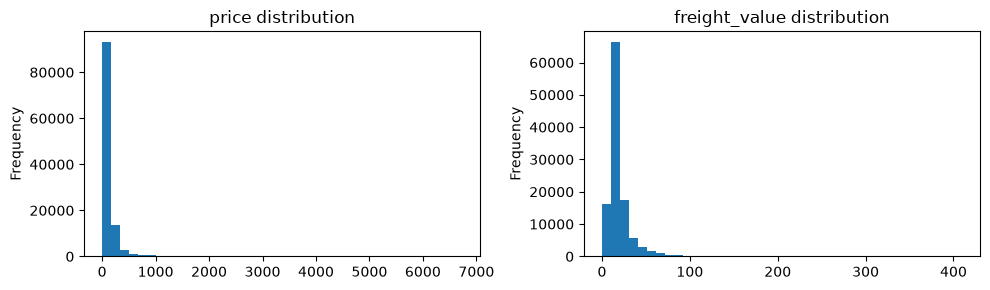

In [33]:
def iqr_summary(series):
    numeric = pd.to_numeric(series, errors="coerce")
    valid = numeric.dropna()
    q1, q3 = valid.quantile([0.25, 0.75]) if len(valid) else (float("nan"), float("nan"))
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((valid < lower) | (valid > upper)).sum()
    return {
        "valid_values": len(valid), "not_numeric_or_missing": int(numeric.isna().sum()),
        "min": valid.min() if len(valid) else float("nan"),
        "median": valid.median() if len(valid) else float("nan"),
        "max": valid.max() if len(valid) else float("nan"),
        "q1": q1, "q3": q3, "iqr_lower_fence": lower, "iqr_upper_fence": upper,
        "potential_iqr_outliers": int(outliers),
    }
price_freight_summary = pd.DataFrame({
    name: iqr_summary(dfs["order_items"][name]) for name in ["price", "freight_value"]
}).T
display(price_freight_summary)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for axis, column in zip(axes, ["price", "freight_value"]):
    pd.to_numeric(dfs["order_items"][column], errors="coerce").dropna().plot.hist(
        bins=40, ax=axis, title=f"{column} distribution"
    )
plt.tight_layout()
plt.show()

In [34]:
display(Markdown(f"**Interpretation.** The IQR rule flags {int(price_freight_summary.loc['price', 'potential_iqr_outliers']):,} price values and {int(price_freight_summary.loc['freight_value', 'potential_iqr_outliers']):,} freight values as potential outliers. These are review flags only; no observations are removed or recoded."))

**Interpretation.** The IQR rule flags 8,427 price values and 12,134 freight values as potential outliers. These are review flags only; no observations are removed or recoded.

## Question 15 — What is the distribution of delivery duration?

In [35]:
orders = dfs["orders"]
purchase_time = pd.to_datetime(orders["order_purchase_timestamp"], errors="coerce")
delivered_time = pd.to_datetime(orders["order_delivered_customer_date"], errors="coerce")
delivered_mask = orders["order_status"].eq("delivered")
duration_hours = (delivered_time - purchase_time).dt.total_seconds() / 3600
valid_delivery = delivered_mask & purchase_time.notna() & delivered_time.notna() & duration_hours.ge(0)
delivery_duration_days = duration_hours[valid_delivery] / 24
print(f"Valid delivered orders with both timestamps and non-negative duration: {int(valid_delivery.sum()):,}")
print(f"Delivered orders missing/unparseable timestamps or with negative duration: {int((delivered_mask & ~valid_delivery).sum()):,}")
display(delivery_duration_days.describe().to_frame("delivery_days").T)

Valid delivered orders with both timestamps and non-negative duration: 96,470
Delivered orders missing/unparseable timestamps or with negative duration: 8


,count,mean,std,min,25%,50%,75%,max
delivery_days,96470.0,12.558217,9.546156,0.533414,6.766204,10.217477,15.720182,209.628611


In [36]:
display(Markdown(f"**Interpretation.** Duration is calculated only for delivered orders with both timestamps parsed and a non-negative elapsed time. This leaves {len(delivery_duration_days):,} valid observations; the displayed statistics describe days from purchase to customer delivery."))

**Interpretation.** Duration is calculated only for delivered orders with both timestamps parsed and a non-negative elapsed time. This leaves 96,470 valid observations; the displayed statistics describe days from purchase to customer delivery.

## Question 16 — Are there timestamp inconsistencies?

In [37]:
timestamp_columns = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
parsed_times = {column: pd.to_datetime(dfs["orders"][column], errors="coerce") for column in timestamp_columns}
parse_report = pd.DataFrame([
    {"column": column, "missing_or_unparseable": int(values.isna().sum()), "rows": len(values)}
    for column, values in parsed_times.items()
])
chronology_checks = [
    ("purchase_after_approval", "order_purchase_timestamp", "order_approved_at"),
    ("approval_after_carrier_handoff", "order_approved_at", "order_delivered_carrier_date"),
    ("carrier_handoff_after_delivery", "order_delivered_carrier_date", "order_delivered_customer_date"),
]
chronology_report = pd.DataFrame([
    {"check": label, "comparable_rows": int((parsed_times[left].notna() & parsed_times[right].notna()).sum()),
     "violations": int((parsed_times[left] > parsed_times[right]).sum())}
    for label, left, right in chronology_checks
])
display(parse_report)
display(chronology_report)

,column,missing_or_unparseable,rows
0,order_purchase_timestamp,0,99441
1,order_approved_at,160,99441
2,order_delivered_carrier_date,1783,99441
3,order_delivered_customer_date,2965,99441
4,order_estimated_delivery_date,0,99441


,check,comparable_rows,violations
0,purchase_after_approval,99281,0
1,approval_after_carrier_handoff,97644,1359
2,carrier_handoff_after_delivery,96475,23


In [38]:
display(Markdown(f"**Interpretation.** Among the chronological pairs where both values are present and parseable, the checks find {int(chronology_report.violations.sum()):,} ordering violations in total. Missing timestamps are reported separately and are not replaced with zero; estimated delivery is not treated as a required event in the chronology."))

**Interpretation.** Among the chronological pairs where both values are present and parseable, the checks find 1,382 ordering violations in total. Missing timestamps are reported separately and are not replaced with zero; estimated delivery is not treated as a required event in the chronology.

## Question 17 — How many geolocation records exist per ZIP prefix?

In [39]:
geo = dfs["geolocation"]
geo_by_zip = geo["geolocation_zip_code_prefix"].value_counts(dropna=False)
geo_zip_summary = pd.Series({
    "geolocation_records": len(geo),
    "distinct_non_null_zip_prefixes": geo["geolocation_zip_code_prefix"].nunique(dropna=True),
    "maximum_records_for_one_prefix": int(geo_by_zip.max()) if len(geo_by_zip) else 0,
    "prefixes_with_multiple_records": int((geo_by_zip > 1).sum()),
})
display(geo_zip_summary.to_frame("value"))
display(geo_by_zip.head(10).rename_axis("geolocation_zip_code_prefix").rename("records").to_frame())

,value
geolocation_records,1000163
distinct_non_null_zip_prefixes,19015
maximum_records_for_one_prefix,1146
prefixes_with_multiple_records,17972


,records
geolocation_zip_code_prefix,
24220,1146
24230,1102
38400,965
35500,907
11680,879
22631,832
30140,810
11740,788
38408,773


In [40]:
display(Markdown(f"**Interpretation.** The geolocation table contains {len(geo):,} records and {geo['geolocation_zip_code_prefix'].nunique(dropna=True):,} distinct non-null ZIP prefixes. {int((geo_by_zip > 1).sum()):,} prefix values occur more than once, confirming ZIP prefix is not a unique row identifier."))

**Interpretation.** The geolocation table contains 1,000,163 records and 19,015 distinct non-null ZIP prefixes. 17,972 prefix values occur more than once, confirming ZIP prefix is not a unique row identifier.

## Findings summary

In [41]:
# Findings are assembled from the calculations above; no expected values are hardcoded.
top_status = status_counts.iloc[0]
top_category = category_counts.iloc[0]
findings = [
    f"- Dataset sizes range from {int(dataset_sizes.rows.min()):,} rows ({dataset_sizes.loc[dataset_sizes.rows.idxmin(), 'table']}) to {int(dataset_sizes.rows.max()):,} rows ({dataset_sizes.loc[dataset_sizes.rows.idxmax(), 'table']}).",
    f"- {len(missing_values)} columns contain missing values ({int(missing_values.null_count.sum()) if not missing_values.empty else 0:,} missing cells); there are {total_full_row_duplicates:,} extra full-row duplicates.",
    f"- {len(nonunique_expected)} configured candidate identifier{'s' if len(nonunique_expected) != 1 else ''} {'contain' if len(nonunique_expected) != 1 else 'contains'} repeated key values ({nonunique_details}); geolocation has no unique key configured and ZIP prefixes repeat.",
    f"- The most frequent order status is {top_status.order_status} ({int(top_status.orders):,}); the most common product category by product rows is {top_category.product_category_name} ({int(top_category.product_rows):,}).",
    f"- {len(repeat_customers):,} persistent customers have multiple distinct orders; {len(orders_without_items):,} orders have no item rows and {len(orders_without_payments):,} have no payment rows.",
    f"- Geolocation has {int(geo_zip_summary['distinct_non_null_zip_prefixes']):,} ZIP prefixes, with up to {int(geo_zip_summary['maximum_records_for_one_prefix']):,} records for a prefix; ZIP prefixes are not unique keys.",
    f"- IQR flags {int(price_freight_summary.loc['price', 'potential_iqr_outliers']):,} prices and {int(price_freight_summary.loc['freight_value', 'potential_iqr_outliers']):,} freight values for review; {int(chronology_report.violations.sum()):,} checked timestamp-order violations were observed.",
    "- Follow-up for D1-T10/D1-T11: validate candidate keys and relationship coverage, review missingness and timestamp anomalies, and investigate IQR flags in context. These descriptive results do not establish causes.",
]
display(Markdown("\n".join(findings)))

- Dataset sizes range from 71 rows (category_translation) to 1,000,163 rows (geolocation).
- 13 columns contain missing values (153,259 missing cells); there are 261,831 extra full-row duplicates.
- 1 configured candidate identifier contains repeated key values (reviews: 814); geolocation has no unique key configured and ZIP prefixes repeat.
- The most frequent order status is delivered (96,478); the most common product category by product rows is cama_mesa_banho (3,029).
- 2,997 persistent customers have multiple distinct orders; 775 orders have no item rows and 1 have no payment rows.
- Geolocation has 19,015 ZIP prefixes, with up to 1,146 records for a prefix; ZIP prefixes are not unique keys.
- IQR flags 8,427 prices and 12,134 freight values for review; 1,382 checked timestamp-order violations were observed.
- Follow-up for D1-T10/D1-T11: validate candidate keys and relationship coverage, review missingness and timestamp anomalies, and investigate IQR flags in context. These descriptive results do not establish causes.

## D1-T10 — Relationship validation

This section checks the specified child-to-parent key relationships and candidate-key uniqueness using the loaded raw tables. For relationship comparisons, null key values are excluded from both key sets and counted separately in the report; no rows are deleted or silently removed. Orphan counts are distinct non-null child keys absent from the distinct non-null parent key set, with sample values included.

Geolocation is a non-unique lookup: customer and seller ZIP-prefix coverage is checked against the set of distinct non-null geolocation prefixes, while raw prefix multiplicity is separately reported. Geolocation is not treated as a unique-key parent.

Items, payments, and reviews retain their own table grains. Their per-order metrics are calculated independently; order items and payments are never joined directly, avoiding row multiplication.

### Foreign-key coverage and candidate-key uniqueness

In [42]:
import json

relationship_specs = [
    ("orders_customer", "orders", "customer_id", "customers", "customer_id", "foreign_key"),
    ("order_items_order", "order_items", "order_id", "orders", "order_id", "foreign_key"),
    ("payments_order", "payments", "order_id", "orders", "order_id", "foreign_key"),
    ("reviews_order", "reviews", "order_id", "orders", "order_id", "foreign_key"),
    ("order_items_product", "order_items", "product_id", "products", "product_id", "foreign_key"),
    ("order_items_seller", "order_items", "seller_id", "sellers", "seller_id", "foreign_key"),
    ("products_category_translation", "products", "product_category_name", "category_translation", "product_category_name", "foreign_key"),
    ("customer_zip_prefix_coverage", "customers", "customer_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix", "zip_prefix_coverage"),
    ("seller_zip_prefix_coverage", "sellers", "seller_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix", "zip_prefix_coverage"),
]
report_columns = [
    "record_type", "name", "relationship_kind", "child_table", "child_key", "parent_table", "parent_key",
    "orphan_distinct_count", "orphan_sample_values", "child_null_key_rows", "parent_null_key_rows",
    "parent_key_rows", "parent_distinct_keys", "parent_duplicate_extra_rows", "validation_status",
    "candidate_key", "candidate_columns", "row_count", "null_key_rows", "distinct_complete_keys",
    "duplicate_extra_rows", "candidate_is_unique", "metric", "metric_values", "notes",
]
report_rows=[]
def add_row(**values):
    row={column:None for column in report_columns}
    row.update(values)
    report_rows.append(row)

for name, child_table, child_key, parent_table, parent_key, relationship_kind in relationship_specs:
    child_series=dfs[child_table][child_key]
    parent_series=dfs[parent_table][parent_key]
    child_values=set(child_series.dropna().tolist())
    parent_values=set(parent_series.dropna().tolist())
    orphan_values=sorted(child_values-parent_values,key=str)
    parent_rows=int(parent_series.notna().sum())
    parent_distinct=len(parent_values)
    note="Null keys excluded consistently from set comparison and counted separately; no rows removed."
    if parent_table=="geolocation":
        note += " ZIP-prefix coverage uses distinct raw geolocation prefixes; the raw parent is non-unique."
    add_row(
        record_type="relationship", name=name, relationship_kind=relationship_kind, child_table=child_table, child_key=child_key,
        parent_table=parent_table, parent_key=parent_key,
        orphan_distinct_count=len(orphan_values),
        orphan_sample_values=json.dumps(orphan_values[:10],ensure_ascii=False),
        child_null_key_rows=int(child_series.isna().sum()),
        parent_null_key_rows=int(parent_series.isna().sum()),
        parent_key_rows=parent_rows, parent_distinct_keys=parent_distinct,
        parent_duplicate_extra_rows=parent_rows-parent_distinct,
        validation_status="FAIL" if orphan_values else "PASS", notes=note,
    )

for table,key_spec in DEFAULT_KEY_MAP.items():
    keys=[key_spec] if isinstance(key_spec,str) else list(key_spec)
    complete_mask=dfs[table][keys].notna().all(axis=1)
    complete=dfs[table].loc[complete_mask,keys]
    null_rows=int((~complete_mask).sum())
    duplicate_extras=int(complete.duplicated(subset=keys).sum())
    distinct_keys=int(complete.drop_duplicates().shape[0])
    if null_rows and duplicate_extras: status="DUPLICATES_AND_NULLS"
    elif duplicate_extras: status="DUPLICATES_FOUND"
    elif null_rows: status="NULL_KEY_ROWS"
    else: status="UNIQUE"
    add_row(
        record_type="candidate_key", name=f"{table}_candidate_key",
        candidate_key=", ".join(keys), candidate_columns=json.dumps(keys),
        row_count=len(dfs[table]), null_key_rows=null_rows,
        distinct_complete_keys=distinct_keys, duplicate_extra_rows=duplicate_extras,
        candidate_is_unique=(null_rows==0 and duplicate_extras==0), validation_status=status,
        notes="Duplicate extras count repeated complete key rows beyond the first; null-key rows are reported separately.",
    )

cardinality_rows=[]
def add_metric(name,values,notes):
    row={column:None for column in report_columns}
    row.update(record_type="cardinality_metric",name=name,metric=name,
               metric_values=json.dumps(values,ensure_ascii=False,default=str),notes=notes)
    cardinality_rows.append(row)

items_per_order=dfs["order_items"].groupby("order_id").size()
payments_per_order=dfs["payments"].groupby("order_id").size()
review_counts_per_order=dfs["reviews"].groupby("order_id").size()
reviews_per_order_frequency=review_counts_per_order.value_counts().sort_index()
customer_records_per_persistent_id=dfs["customers"].groupby("customer_unique_id").size()
geolocation_records_per_zip=dfs["geolocation"].groupby("geolocation_zip_code_prefix").size()
add_metric("items_per_order_describe",items_per_order.describe().to_dict(),
           f"groupby('order_id').size().describe(); null order IDs excluded from groupby and separately reported: {int(dfs['order_items']['order_id'].isna().sum())}.")
add_metric("payments_per_order_describe",payments_per_order.describe().to_dict(),
           f"groupby('order_id').size().describe(); null order IDs excluded from groupby and separately reported: {int(dfs['payments']['order_id'].isna().sum())}.")
add_metric("reviews_per_order_frequency",{str(int(k)):int(v) for k,v in reviews_per_order_frequency.items()},
           f"value_counts() of per-order review counts; null order IDs excluded from groupby and separately reported: {int(dfs['reviews']['order_id'].isna().sum())}.")
order_ids=set(dfs["orders"]["order_id"].dropna().tolist())
item_order_ids=set(dfs["order_items"]["order_id"].dropna().tolist())
payment_order_ids=set(dfs["payments"]["order_id"].dropna().tolist())
orders_without_items=sorted(order_ids-item_order_ids)
orders_without_payments=sorted(order_ids-payment_order_ids)
add_metric("orders_without_items",{"distinct_order_count":len(orders_without_items),"sample_order_ids":orders_without_items[:10]},
           "Distinct non-null order IDs compared as sets; item rows are not joined to payment rows.")
add_metric("orders_without_payments",{"distinct_order_count":len(orders_without_payments),"sample_order_ids":orders_without_payments[:10]},
           "Distinct non-null order IDs compared as sets; payment rows are not joined to item rows.")
add_metric("customer_records_per_customer_unique_id_describe",customer_records_per_persistent_id.describe().to_dict(),
           f"groupby('customer_unique_id').size().describe(); null customer_unique_id rows reported separately: {int(dfs['customers']['customer_unique_id'].isna().sum())}.")
add_metric("geolocation_records_per_zip_prefix_describe",geolocation_records_per_zip.describe().to_dict(),
           f"groupby('geolocation_zip_code_prefix').size().describe(); null ZIP-prefix rows reported separately: {int(dfs['geolocation']['geolocation_zip_code_prefix'].isna().sum())}. Raw ZIP prefixes are non-unique.")
add_metric("geolocation_zip_prefix_multiplicity",{
    "raw_geolocation_rows":len(dfs["geolocation"]),
    "non_null_zip_prefix_rows":int(dfs["geolocation"]["geolocation_zip_code_prefix"].notna().sum()),
    "distinct_non_null_zip_prefixes":int(dfs["geolocation"]["geolocation_zip_code_prefix"].nunique(dropna=True)),
    "prefixes_with_multiple_records":int((geolocation_records_per_zip>1).sum()),
    "duplicate_extra_prefix_rows":int(geolocation_records_per_zip.sum()-geolocation_records_per_zip.size),
},"Raw geolocation multiplicity is separate from ZIP-prefix referential coverage; geolocation is not a unique-key parent.")

relationship_report=pd.DataFrame(report_rows+cardinality_rows).reindex(columns=report_columns)
report_dir=PROJECT_ROOT/"reports"/"profiling"
report_dir.mkdir(parents=True,exist_ok=True)
relationship_report_path=report_dir/"relationship_report.csv"
relationship_report.to_csv(relationship_report_path,index=False)
relationship_summary=relationship_report[relationship_report.record_type=="relationship"]
key_summary=relationship_report[relationship_report.record_type=="candidate_key"]
cardinality_summary=relationship_report[relationship_report.record_type=="cardinality_metric"]
display(relationship_summary[["name","orphan_distinct_count","child_null_key_rows","validation_status"]])
display(key_summary[["name","candidate_key","null_key_rows","duplicate_extra_rows","validation_status"]])
display(cardinality_summary[["metric","metric_values"]])
print(f"Saved {len(relationship_report)} report rows to {relationship_report_path}")

,name,orphan_distinct_count,child_null_key_rows,validation_status
0,orders_customer,0.0,0.0,PASS
1,order_items_order,0.0,0.0,PASS
2,payments_order,0.0,0.0,PASS
3,reviews_order,0.0,0.0,PASS
4,order_items_product,0.0,0.0,PASS
5,order_items_seller,0.0,0.0,PASS
6,products_category_translation,2.0,610.0,FAIL
7,customer_zip_prefix_coverage,157.0,0.0,FAIL
8,seller_zip_prefix_coverage,7.0,0.0,FAIL


,name,candidate_key,null_key_rows,duplicate_extra_rows,validation_status
9,orders_candidate_key,order_id,0.0,0.0,UNIQUE
10,customers_candidate_key,customer_id,0.0,0.0,UNIQUE
11,order_items_candidate_key,"order_id, order_item_id",0.0,0.0,UNIQUE
12,payments_candidate_key,"order_id, payment_sequential",0.0,0.0,UNIQUE
13,reviews_candidate_key,review_id,0.0,814.0,DUPLICATES_FOUND
14,products_candidate_key,product_id,0.0,0.0,UNIQUE
15,sellers_candidate_key,seller_id,0.0,0.0,UNIQUE
16,category_translation_candidate_key,product_category_name,0.0,0.0,UNIQUE


,metric,metric_values
17,items_per_order_describe,"{""count"": 98666.0, ""mean"": 1.1417306873695092,..."
18,payments_per_order_describe,"{""count"": 99440.0, ""mean"": 1.0447103781174578,..."
19,reviews_per_order_frequency,"{""1"": 98126, ""2"": 543, ""3"": 4}"
20,orders_without_items,"{""distinct_order_count"": 775, ""sample_order_id..."
21,orders_without_payments,"{""distinct_order_count"": 1, ""sample_order_ids""..."
22,customer_records_per_customer_unique_id_describe,"{""count"": 96096.0, ""mean"": 1.0348089410589412,..."
23,geolocation_records_per_zip_prefix_describe,"{""count"": 19015.0, ""mean"": 52.598632658427555,..."
24,geolocation_zip_prefix_multiplicity,"{""raw_geolocation_rows"": 1000163, ""non_null_zi..."


Saved 25 report rows to D:\Insight360\reports\profiling\relationship_report.csv


### Relationship/cardinality interpretations

In [43]:
failed_relationships=relationship_summary.loc[relationship_summary.validation_status=="FAIL","name"].tolist()
non_unique_mask=~key_summary.candidate_is_unique.astype("boolean").fillna(False)
non_unique_candidates=key_summary.loc[non_unique_mask,"name"].tolist()
geo_unique_prefixes=int(dfs["geolocation"]["geolocation_zip_code_prefix"].nunique(dropna=True))
display(Markdown(
    f"**D1-T10 interpretation.** {len(failed_relationships)} of {len(relationship_summary)} relationship coverage checks have orphan keys: {', '.join(failed_relationships) if failed_relationships else 'none'}. "
    f"Candidate key checks flagged {', '.join(non_unique_candidates) if non_unique_candidates else 'none'} as non-unique or incomplete. "
    f"There are {len(orders_without_items):,} orders without item rows and {len(orders_without_payments):,} without payment rows. "
    f"Geolocation has {len(dfs['geolocation']):,} raw rows and {geo_unique_prefixes:,} distinct non-null ZIP prefixes; ZIP-prefix coverage uses distinct prefixes, not raw-row uniqueness. "
    f"Item, payment, and review cardinalities were calculated separately without directly joining items to payments."
))

**D1-T10 interpretation.** 3 of 9 relationship coverage checks have orphan keys: products_category_translation, customer_zip_prefix_coverage, seller_zip_prefix_coverage. Candidate key checks flagged reviews_candidate_key as non-unique or incomplete. There are 775 orders without item rows and 1 without payment rows. Geolocation has 1,000,163 raw rows and 19,015 distinct non-null ZIP prefixes; ZIP-prefix coverage uses distinct prefixes, not raw-row uniqueness. Item, payment, and review cardinalities were calculated separately without directly joining items to payments.